# Prediction and the app · Yashaswini
**Project 24 · Activity Recognition System · Review 2.** Run the cells top to bottom (Jupyter: kernel *har*; Colab: run the setup cell first, it fetches the data and models).

In [1]:
import os, sys, subprocess, pathlib, urllib.request, zipfile, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if not os.path.exists("/content/activity-recognition"):
        subprocess.run(["git", "clone", "-q", "https://github.com/rajyyug1132/activity-recognition", "/content/activity-recognition"], check=True)
    os.chdir("/content/activity-recognition")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mediapipe", "scikit-learn==1.9.1"], check=True)
    os.makedirs("data/uci", exist_ok=True); os.makedirs("models", exist_ok=True)
    if not os.path.exists("data/uci/UCI HAR Dataset"):
        urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip", "data/uci/har.zip")
        zipfile.ZipFile("data/uci/har.zip").extractall("data/uci")
        zipfile.ZipFile("data/uci/UCI HAR Dataset.zip").extractall("data/uci")
    if not os.path.exists("models/pose_landmarker_full.task"):
        urllib.request.urlretrieve("https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task", "models/pose_landmarker_full.task")
    from google.colab import drive
    drive.mount("/content/drive")
    for f in ["cnn_uci.keras", "video_rf.joblib"]:
        if os.path.exists(f"/content/drive/MyDrive/{f}"):
            subprocess.run(["cp", f"/content/drive/MyDrive/{f}", f"models/{f}"], check=True)
elif pathlib.Path.cwd().name == "notebooks":
    os.chdir("..")                      # run from the repository root

sys.path.insert(0, "src")
for f in ["config/config.yaml", "app/demo/uci_test_person_12.csv", "data/uci/UCI HAR Dataset",
          "models/cnn_uci.keras", "models/video_rf.joblib", "models/pose_landmarker_full.task"]:
    print("found  " if os.path.exists(f) else "MISSING", f)

found   config/config.yaml
found   app/demo/uci_test_person_12.csv
found   data/uci/UCI HAR Dataset
found   models/cnn_uci.keras
found   models/video_rf.joblib
found   models/pose_landmarker_full.task


In [2]:
%matplotlib inline
import inspect, yaml, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Code, Image, display
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def show(fn):
    """Print a function's source exactly as it is in src/."""
    display(Code(inspect.getsource(fn), language="python"))

cfg = yaml.safe_load(open("config/config.yaml"))
DEMO = "app/demo/uci_test_person_12.csv"
NAMES = {"WALKING": "Walking", "WALKING_UPSTAIRS": "Upstairs", "WALKING_DOWNSTAIRS": "Downstairs",
         "SITTING": "Sitting", "STANDING": "Standing", "LAYING": "Lying"}
COLOURS = {"WALKING": "#2bb3a3", "WALKING_DOWNSTAIRS": "#2b3a8f", "WALKING_UPSTAIRS": "#7fb8e6",
           "SITTING": "#e9853a", "STANDING": "#e8c547", "LAYING": "#7a2e6e"}

## 5. Prediction and the app · Yashaswini
**What to say**
- `predict_csv` is the path every recording takes: windows, normalise, the CNN, then one row per window with a start time, an activity and a confidence.
- `smooth` is a majority vote over five windows. It removes one-window flickers such as walk, sit, walk.
- The app calls exactly these functions. Below they run on the sample recording: two minutes of UCI test person 12, whom the model never trained on.

In [3]:
from inference import predict_csv, smooth
show(predict_csv)
show(smooth)

def predict_csv(path, model, cfg) -> pd.DataFrame:
    """One row per window: start_time, activity, confidence.

    `path` can be a file path or a file-like object (Streamlit upload).
    `model.predict(X)` must return class probabilities [N, 6].
    """
    df = pd.read_csv(path) if not isinstance(path, pd.DataFrame) else path
    X = normalize(to_windows(df, cfg), cfg["norm_stats"])
    if len(X) == 0:
        return pd.DataFrame(columns=["start_time", "activity", "confidence"])
    p = model.predict(X, verbose=0) if hasattr(model, "compile") else model.predict(X)
    step = cfg["window_samples"] * (1 - cfg["overlap"]) / cfg["sampling_rate_hz"]
    return pd.DataFrame({"start_time": df["timestamp"].min() + np.arange(len(X)) * step,
                         "activity": [ACTS[i] for i in p.argmax(1)],
                         "confidence": p.max(1).round(3)})

def smooth(pred_df, k=5) -> pd.DataFrame:
    """Centered rolling majority vote over `activity` (odd k, edges use a shorter window).

    Ties keep the original label if it is among the leaders. Returns a copy.
    """
    assert k % 2 == 1, "k must be odd"
    out, acts, h = pred_df.copy(), list(pred_df["activity"]), k // 2
    for i, orig in enumerate(acts):
        win = acts[max(0, i - h): i + h + 1]
        counts = {a: win.count(a) for a in set(win)}
        top = max(counts.values())
        if counts[orig] < top:
            out.iloc[i, out.columns.get_loc("activity")] = next(a for a in win if counts[a] == top)
    return out

In [4]:
import tensorflow as tf
from preprocess import normalize
from inference import ACTS
tf.get_logger().setLevel("ERROR")
model = tf.keras.models.load_model("models/cnn_uci.keras")

95 windows, 99% right


,start_time,activity,confidence,truth
0,0.00,WALKING,0.605,WALKING
1,1.28,WALKING,0.956,WALKING
2,2.56,WALKING,0.951,WALKING
3,3.84,WALKING,0.875,WALKING
4,5.12,WALKING,0.913,WALKING
5,6.40,WALKING,0.877,WALKING


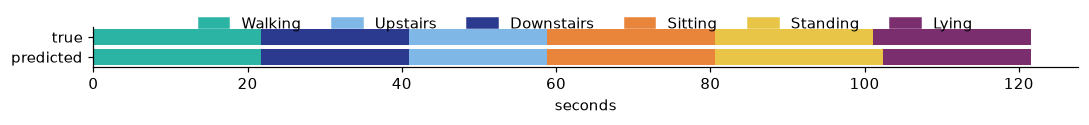

In [5]:
p = smooth(predict_csv(DEMO, model, cfg), cfg["smooth_window"])
# the sample was built from these stretches of person 12's recording (see README)
TRUTH = [("WALKING", 0, 23.04), ("WALKING_DOWNSTAIRS", 23.04, 41), ("WALKING_UPSTAIRS", 41, 59),
         ("SITTING", 59, 81), ("STANDING", 81, 102), ("LAYING", 102, 124.2)]
p["truth"] = [next((a for a, s, e in TRUTH if s <= t + 1.28 < e), None) for t in p.start_time]
print(f"{len(p)} windows, {(p.activity == p.truth).mean():.0%} right")
display(p.head(6))
fig, ax = plt.subplots(figsize=(10, 1.9))
for row, col in ((1, "truth"), (0, "activity")):
    for t, a in zip(p.start_time, p[col]):
        ax.barh(row, 1.28, left=t, color=COLOURS[a], height=0.8)
ax.set_yticks([0, 1], ["predicted", "true"]); ax.set_xlabel("seconds")
handles = [plt.Rectangle((0, 0), 1, 1, color=COLOURS[a]) for a in ACTS]
ax.legend(handles, [NAMES[a] for a in ACTS], ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.6), frameon=False)
plt.tight_layout(); plt.show()

In [6]:
for i, line in enumerate(open("app/home.py", encoding="utf-8"), 1):
    if any(k in line for k in ("validate_csv(", "predict_csv(", "smooth(")):
        print(f"app/home.py line {i}: {line.strip()}")

app/home.py line 125: rep = validate_csv(df, cfg)
app/home.py line 136: pred = predict_csv(df, model, cfg)
app/home.py line 138: pred = smooth(pred, cfg["smooth_window"])
